# Customers Like You — Analysis Notebook

This notebook documents the reproducible project workflow. Run cells from top to bottom from the `notebooks/` folder. It rebuilds the matrix from the supplied raw workbook, then runs the model evaluation and customer segmentation pipeline. Customer IDs are used internally only; do not publish them.

**Student:** Kamya Kanara  
**Submission date:** October 13, 2026


## 1. Business question and method

GiftLane needs (1) product recommendations based on historical purchasing patterns and (2) a customer map for marketing. The matrix is customer × product. Truncated SVD is the primary method because it works directly on sparse input without centering. PCA is run at the same selected component count for comparison.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
PROJECT = Path('..').resolve()
print('Project root:', PROJECT)
print('Raw workbook exists:', (PROJECT / 'data/raw/online_retail_II.xlsx').exists())

Project root: D:\linear algebra\Customers_Like_You_Kanara_Submission
Raw workbook exists: True


## 2. Rebuild the data pipeline

This cell runs DE1–DE5 using the raw workbook. It profiles columns, applies documented cleaning rules, creates the final-two-month test split, and saves the sparse matrix and reports. It may take a little while.

In [2]:
import subprocess, sys
subprocess.run([sys.executable, str(PROJECT / 'build_matrix.py')], cwd=PROJECT, check=True)

CompletedProcess(args=['d:\\linear algebra\\Customers_Like_You_Kanara_Submission\\.venv\\Scripts\\python.exe', 'D:\\linear algebra\\Customers_Like_You_Kanara_Submission\\build_matrix.py'], returncode=0)

## 3. Inspect data quality and matrix report

In [3]:
display(pd.read_csv(PROJECT / 'data/processed/data_profile.csv', index_col=0))
display(pd.read_csv(PROJECT / 'data/processed/cleaning_log.csv'))
display(pd.read_csv(PROJECT / 'data/processed/matrix_report.csv'))

,dtype,missing,missing_pct,n_unique
Invoice,object,0,0.00,53628
StockCode,object,0,0.00,5305
Description,object,4382,0.41,5698
Quantity,int64,0,0.00,1057
InvoiceDate,datetime64[ns],0,0.00,47635
Price,float64,0,0.00,2807
Customer ID,float64,243007,22.77,5942
Country,object,0,0.00,43


,Rule,Rows_removed
0,Cancellation invoices,19494
1,Non-positive quantity or price,6207
2,Non-product codes,4793
3,Missing Customer ID,234245
4,Duplicate rows,26055
5,TOTAL removed,290794
6,Remaining rows,776577


,shape,non_zeros,sparsity_pct,dense_MB,sparse_MB
0,"(5473, 3687)",413927,97.9487,161.43,3.333


## 4. Fit models, compare recommendations, and build the customer map

The next cell evaluates the requested component counts, writes the PCA-vs-SVD comparison at k=50, and generates the anonymised customer map.

In [4]:
subprocess.run([sys.executable, str(PROJECT / 'run_pipeline.py')], cwd=PROJECT, check=True)

CompletedProcess(args=['d:\\linear algebra\\Customers_Like_You_Kanara_Submission\\.venv\\Scripts\\python.exe', 'D:\\linear algebra\\Customers_Like_You_Kanara_Submission\\run_pipeline.py'], returncode=0)

## 5. Results table

In [5]:
display(pd.read_csv(PROJECT / 'outputs/tables/component_curve.csv'))
display(pd.read_csv(PROJECT / 'outputs/tables/pca_vs_svd.csv'))

,method,k,relative_reconstruction_error_estimate,explained_variance_ratio
0,Truncated SVD,10,0.755857,NaN
1,Truncated SVD,20,0.687104,NaN
2,Truncated SVD,50,0.583754,NaN
3,Truncated SVD,100,0.495101,NaN
4,Truncated SVD,200,0.398925,NaN
5,PCA,10,NaN,0.414827
6,PCA,20,NaN,0.516127
7,PCA,50,NaN,0.650563
8,PCA,100,NaN,0.748617
9,PCA,200,NaN,0.837478


,method,k,fit_seconds,peak_memory_MB_tracemalloc,stored_factors_MB,explained_variance,relative_reconstruction_error_estimate,hit_rate_at_10,ndcg_at_10,eligible_test_customers,component_1_interpretation
0,Truncated SVD,50.0,0.161,4.89,1.832,NaN,0.58405,0.2002,0.0336,1913,Primarily high-volume purchase patterns; verif...
1,PCA,50.0,0.781,4.51,1.832,0.65056,NaN,0.2013,0.0340,1913,"Strongest product loadings: 85099B, 85123A, 21..."
2,Best-seller baseline,NaN,NaN,NaN,NaN,NaN,NaN,0.1929,NaN,1913,Not applicable


## 6. Customer segments and figures

The scatter plot shows customers in a two-component SVD projection. K-means labels are fitted in normalized 50-component space. This two-dimensional projection is only a visual summary and can hide differences present in higher dimensions.

,segment,n_customers,top_products,top_countries
0,Retail Mix Segment 1,1679,WORLD WAR 2 GLIDERS ASSTD DESIGNS | PACK OF 72...,"United Kingdom, Germany, France"
1,Candle & Homeware Buyers,835,WHITE HANGING HEART T-LIGHT HOLDER | ASSORTED ...,"United Kingdom, Cyprus, France"
2,Retail Mix Segment 3,2173,MEDIUM CERAMIC TOP STORAGE JAR | ASSORTED COLO...,"United Kingdom, Germany, France"
3,Bag & Packaging Buyers,786,JUMBO BAG RED RETROSPOT | JUMBO BAG STRAWBERRY...,"United Kingdom, France, Germany"


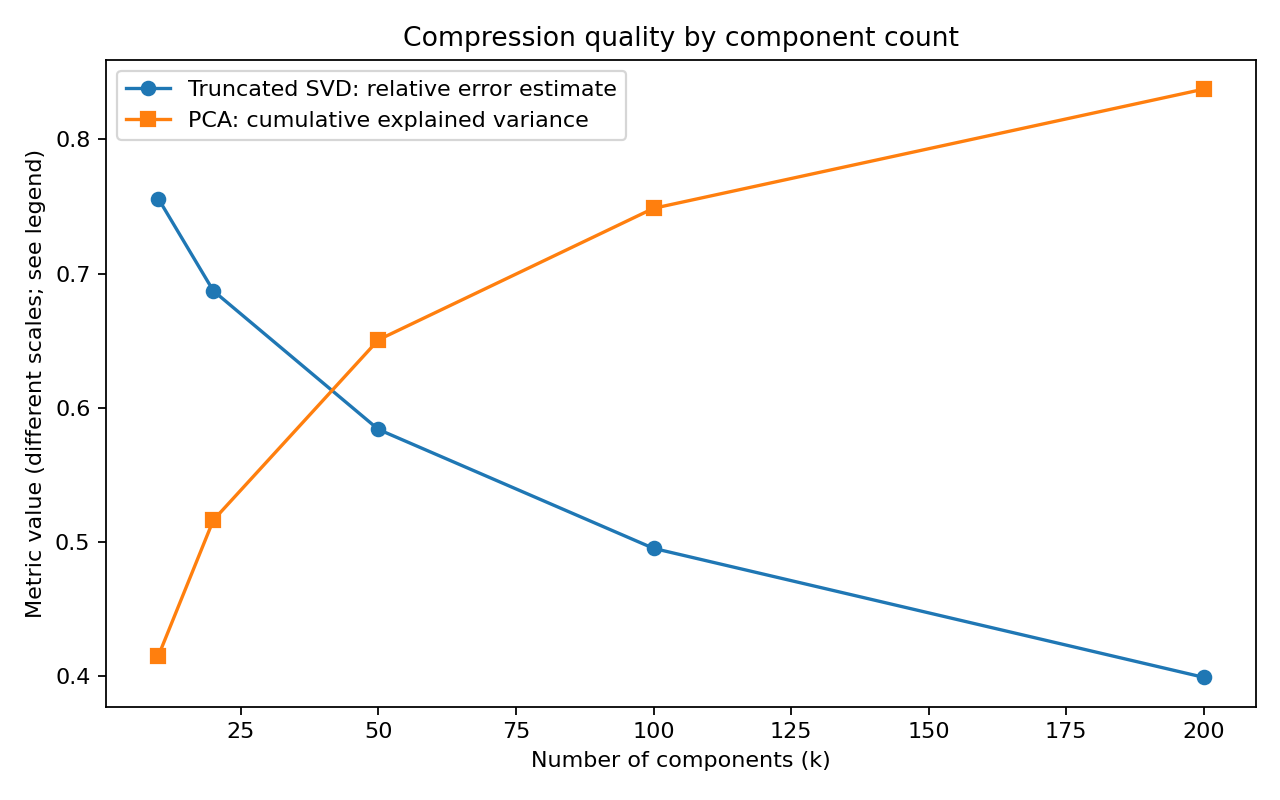

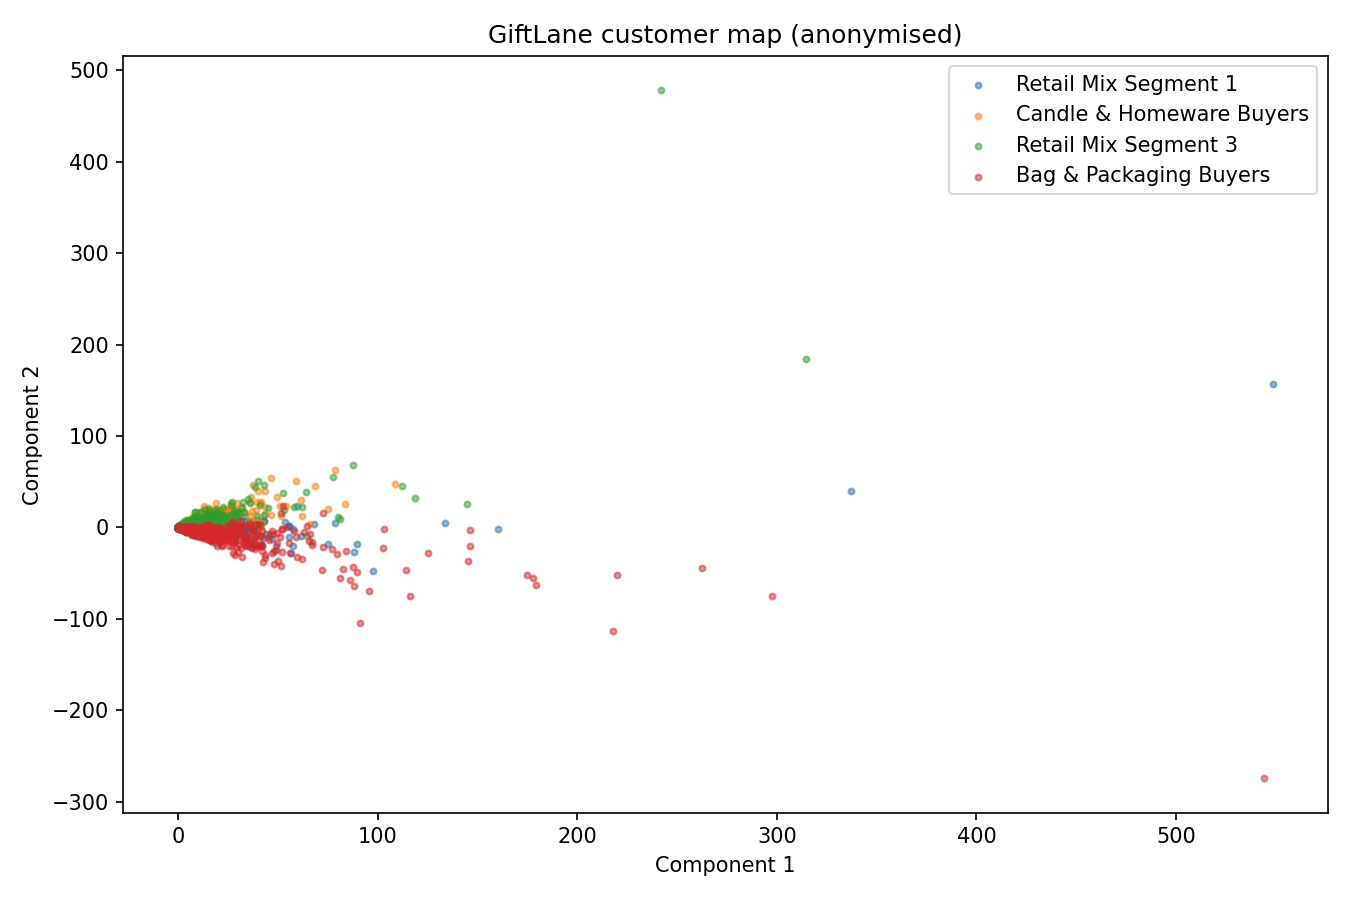

In [6]:
display(pd.read_csv(PROJECT / 'outputs/tables/segments.csv'))
display(Image(filename=str(PROJECT / 'outputs/figures/component_curve.png')))
display(Image(filename=str(PROJECT / 'outputs/figures/customer_map.png')))